In [10]:
import json
from pathlib import Path
import sys

sys.argv = [""]

import numpy as np
import torch
import arviz as az
import matplotlib.pyplot as plt
import xarray
from ICIW_Plots import figure, make_rect_ax, make_square_ax, cm2inch
from scipy.stats.qmc import LatinHypercube, scale

plt.style.use("ICIWstyle")

In [11]:
from HSA_Cam_B_021_pyro import (
    predict,
    calculate_partial_pressures,
    kl_divergence_between_models,
)
from HSA_Mo_B_009_pyro import kinetics_model, generate_synthetic_data

In [12]:
params = {
    "T": (500.0, 600.0),
    "p": (2.0, 20.0),
    "c2h": (0.5, 2.0),
    "f": (10.0, 1000.0),
    "c2i": (0.1, 1.0),
}

# Generate the space filling design points

In [13]:
num_samples = 1000
LHsampler = LatinHypercube(d=len(params))
samples = LHsampler.random(n=num_samples)
samples = scale(
    samples, [v[0] for v in params.values()], [v[1] for v in params.values()]
)

samples = xarray.DataArray(
    data=samples,
    dims=["sample", "parameter"],
    coords={"parameter": list(params.keys())},
)
display(samples)

<xarray.DataArray (sample: 1000, parameter: 5)> Size: 40kB
array([[5.81603455e+02, 5.94660401e+00, 1.98925721e+00, 5.22557343e+02,
        9.68187338e-01],
       [5.66472980e+02, 9.93294369e+00, 1.54530224e+00, 3.11034324e+02,
        8.86374290e-01],
       [5.55440912e+02, 1.88331995e+01, 6.42830089e-01, 6.52141075e+02,
        3.07182196e-01],
       ...,
       [5.00034210e+02, 1.89035630e+01, 1.34883092e+00, 2.22924580e+02,
        3.31306123e-01],
       [5.23344170e+02, 1.08014767e+01, 1.37737625e+00, 6.22936363e+02,
        9.53783716e-01],
       [5.99095775e+02, 1.78334807e+01, 6.33933488e-01, 5.60078000e+02,
        8.22587963e-01]], shape=(1000, 5))
Coordinates:
  * parameter  (parameter) <U3 60B 'T' 'p' 'c2h' 'f' 'c2i'
Dimensions without coordinates: sample

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\density_utils.py:250: RuntimeWarning:

divide by zero encountered in scalar power

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\density_utils.py:246: RuntimeWarning:

divide by zero encountered in scalar divide



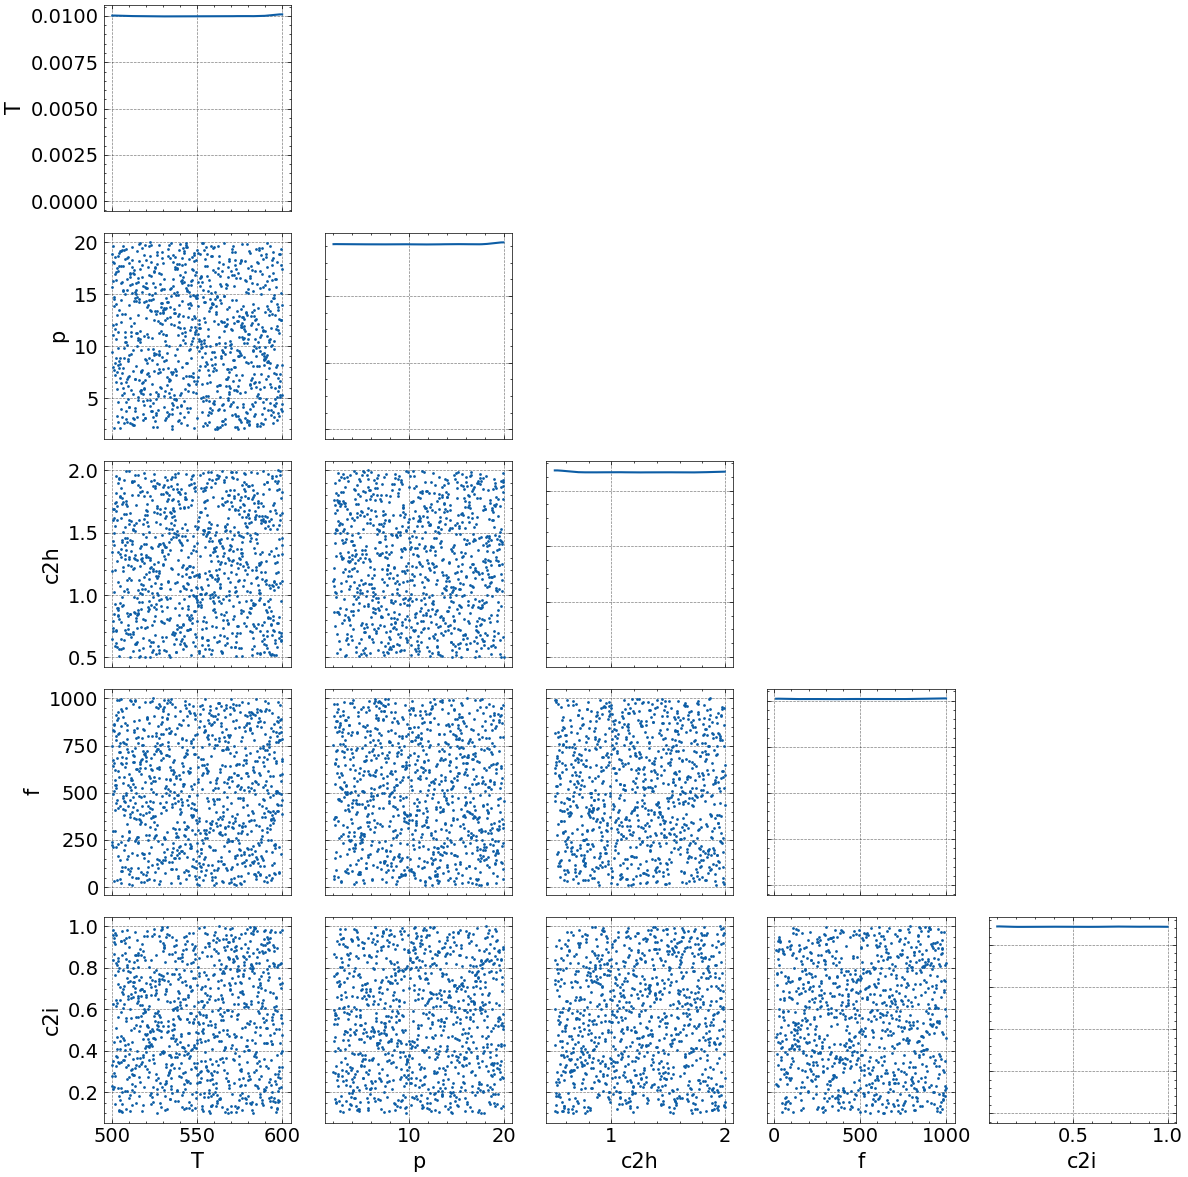

In [14]:
# Convert samples to a format suitable for arviz pair plot
sample_dict = {param: samples.sel(parameter=param).values for param in params.keys()}

az.plot_pair(sample_dict, kind="scatter", marginals=True, figsize=(12, 12))
plt.tight_layout()
plt.show()

Pretty space filling!

## Generate the GT model predictions at these positions

In [15]:
T, p, lat_r = generate_synthetic_data(
    torch.tensor(samples.sel(parameter="T").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="p").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2h").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="f").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2i").values).reshape(-1, 1),
    rel_noise_std=0.0,
)
T, p, obs_r = generate_synthetic_data(
    torch.tensor(samples.sel(parameter="T").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="p").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2h").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="f").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2i").values).reshape(-1, 1),
    rel_noise_std=0.1,
)

array([[<Axes: title={'center': 'lat_r'}>,
        <Axes: title={'center': 'obs_r'}>]], dtype=object)

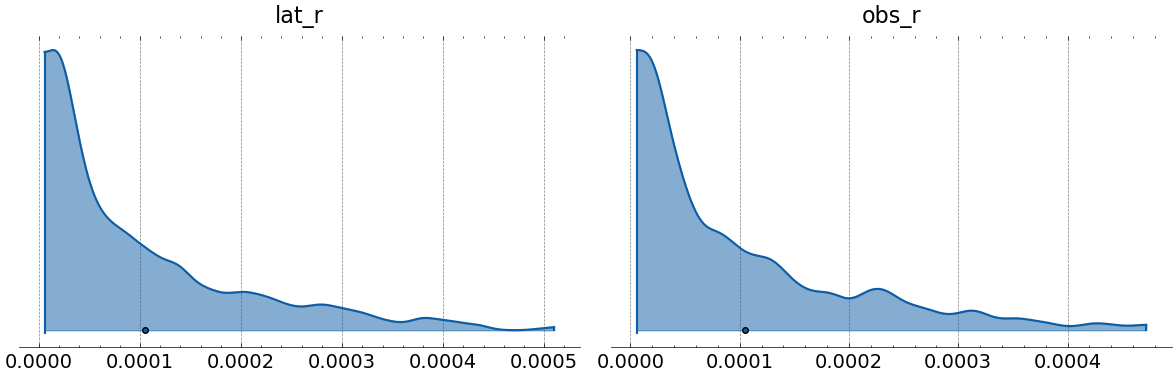

In [16]:
az.plot_density(
    {
        "lat_r": lat_r.numpy().flatten(),
        "obs_r": obs_r.numpy().flatten(),
    },
    figsize=(12, 4),
    hdi_prob=0.999,
    shade=0.5,
)
# ax = plt.gca()
# ax.set_xscale("log")

array([[<Axes: title={'center': 'obs_r'}>,
        <Axes: title={'center': 'lat_r'}>]], dtype=object)

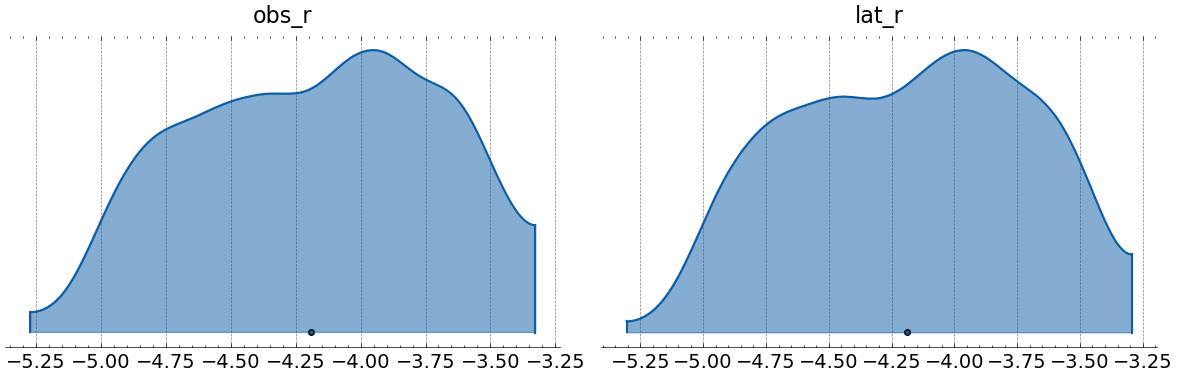

In [17]:
az.plot_density(
    {
        "obs_r": np.log10(obs_r.numpy().flatten()),
        "lat_r": np.log10(lat_r.numpy().flatten()),
    },
    figsize=(12, 4),
    hdi_prob=0.999,
    shade=0.5,
)

In [19]:
data = xarray.Dataset(
    {
        "samples": samples,
        "T": (("sample"), T.numpy().flatten()),
        "p": (("sample", "species"), p.numpy()),
        "latent_r": (("sample"), lat_r.numpy().flatten()),
        "obs_r": (("sample"), obs_r.numpy().flatten()),
    },
    coords={
        "sample": np.arange(num_samples),
        "species": ["CO2", "H2", "H2O", "CH4", "I"],
    },
)
data.attrs["noise"] = "heteroscedastic"
data.attrs["sigma"] = 0.1
display(data)

data.to_netcdf(Path("data/test_heteroscedastic_data_01.nc"))

<xarray.Dataset> Size: 112kB
Dimensions:    (parameter: 5, sample: 1000, species: 5)
Coordinates:
  * parameter  (parameter) <U3 60B 'T' 'p' 'c2h' 'f' 'c2i'
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
Data variables:
    samples    (sample, parameter) float64 40kB 581.6 5.947 ... 560.1 0.8226
    T          (sample) float64 8kB 581.6 566.5 555.4 ... 500.0 523.3 599.1
    p          (sample, species) float64 40kB 2.344 1.178 0.0 ... 0.00839 5.713
    latent_r   (sample) float64 8kB 0.000174 0.0001329 ... 2.905e-05 0.0005103
    obs_r      (sample) float64 8kB 0.0001671 0.0001435 ... 2.805e-05 0.0004643
Attributes:
    noise:    heteroscedastic
    sigma:    0.1